# Рабочая тетрадь №6

In [1]:
import math
import networkx as nx

### 1.1.1 Задание 

Выполните по вариантам соответственно реализацию генетического
алгоритма в соответствии с приложенными начальными данными.

In [2]:
def qZ(x,y):
    return (x - 2 * y - 3) / (x ** 2 + 3 * y ** 2 + 1)


def qSumZ(Z):
    return sum(Z)

In [3]:
def exchangeScheme(oldX, oldY, sortedId):
    X = [0 for i in range(4)]
    Y = [0 for i in range(4)]

    X[2] = oldX[sortedId[2]]
    X[3] = oldX[sortedId[2]]

    X[0] = oldX[sortedId[0]]

    X[1] = oldX[sortedId[1]]

    Y[0] = oldY[sortedId[2]]
    Y[1] = oldY[sortedId[2]]

    Y[2] = oldY[sortedId[0]]

    Y[3] = oldY[sortedId[1]]

    return X,Y

In [4]:
def sorting(Z):
    sortedId = sorted(range(len(Z)), key = lambda k: Z[k])
    return sortedId

In [5]:
def evoStep(X,Y,Z):
    _, minId = min((value, id) for (id, value) in enumerate(Z))
    X = X[:]
    Y = Y[:]
    Z = Z[:]

    X.pop(minId)
    Y.pop(minId)
    Z.pop(minId)

    return X,Y,Z


def evoSteps(X,Y, stepsNum = 4):
    results = []

    for i in range(4):
        arrZ = [qZ(x,Y[i]) for i, x in enumerate(X)]

        X,Y,Z = evoStep(X, Y, arrZ)
        X,Y = exchangeScheme(X,Y, sorting(Z))

        results.append([X,Y, qSumZ(arrZ), arrZ])

    return X, Y, results

In [6]:
X = [-4, -2, 0, 2]
Y = [-1, 1, 0, -2]
results = evoSteps(X,Y)

for i in range(len(results[2])):
    print(f'max_{i+1}_step: {results[2][i][2]}')

qualityArrZ = []

for i in range(len(results[2])):
    qualityArrZ += results[2][i][3]

print(f'max Z:      {max(qualityArrZ)}')

max_1_step: -3.948529411764706
max_2_step: -0.41227180527383367
max_3_step: -0.2720588235294117
max_4_step: 0.37449290060851925
max Z:      0.17647058823529413


### 1.2.1 Задание

Найти длину гамильтонова цикла S4 в полном графе K6 после четырех циклов решения задачи методом отжига по вариантам ниже.

In [7]:
def probability(delta, T):
    return 100 * math.e ** (-delta / T)

In [8]:
def reductTemp(prevT):
    return 0.5 * prevT

In [9]:
def edgeLenghth(i, j, distances, roundTrip=True):
    if roundTrip:
        return max([(item[2] if (item[0] == i and item[1] == j) or
                     (item[1] == i and item[0] == j) else -1)
                    for item in distances])
    else:
        return max([(item[2] if (item[0] == i and item[1] == j) else -1)
                    for item in distances])

In [10]:
def routeLength(V, distances):
    edges = []
    for i in range(len(V) - 1):
        edges.append(edgeLenghth(V[i], V[i + 1], distances))
    return sum(edges)

In [11]:
def routeOneReplacement(arrV, Z, replacementByName=True):
    decrement = 1 if replacementByName else 0
    arrV[Z[0] - decrement], arrV[Z[1] - decrement] =\
        arrV[Z[1] - decrement], arrV[Z[0] - decrement]
    return arrV

In [12]:
def routeReplacement(V, Z):
    for z in Z:
        V = routeOneReplacement(V, z)
    return V

In [13]:
def chooseRoute(distances, V, Z, T, P):
    sumLength = routeLength(V, distances)
    arrSum = [sumLength]

    for i in range(len(Z)):
        newV = routeOneReplacement(V[:], Z[i])
        newS = routeLength(newV, distances)
        arrSum.append(newS)
        deltaS = newS - sumLength
        if deltaS > 0:
            p = probability(deltaS, T)
            if p > P[i]:
                V = newV
                sumLength = newS
            else:
                V = newV
                sumLength = newS
        T = reductTemp(T)

    return V, arrSum

In [14]:
def drawRouteGraph(distances, bestRoute):
    newDistances = []
    for i in range(len(bestRoute) - 1):
        for distance in distances:
            if distance[0] == bestRoute[i] and distance[1] == bestRoute[i + 1] \
            or distance[1] == bestRoute[i] and distance[0] == bestRoute[i + 1]:
                newDistances.append(distance)

    graph1 = nx.Graph() 
    graph1.add_weighted_edges_from(newDistances) 

    nx.draw_kamada_kawai(graph1, node_color = '#fb7258', node_size = 2000, with_labels = True)

In [15]:
distances = [(1, 2, 25),
             (1, 3, 41),
             (1, 4, 38),
             (1, 5, 27),
             (1, 6, 20),
             (2, 3, 21),
             (2, 4, 34),
             (2, 5, 39),
             (2, 6, 17),
             (3, 4, 24),
             (3, 5, 40),
             (3, 6, 22),
             (4, 5, 21),
             (4, 6, 21),
             (5, 6, 22)]

V = [1, 3, 5, 4, 6, 2, 1]
Z = [(3, 4),
    (4, 6),
    (5, 2),
    (6, 2)]
P = [41, 60, 85, 60]

T = 100

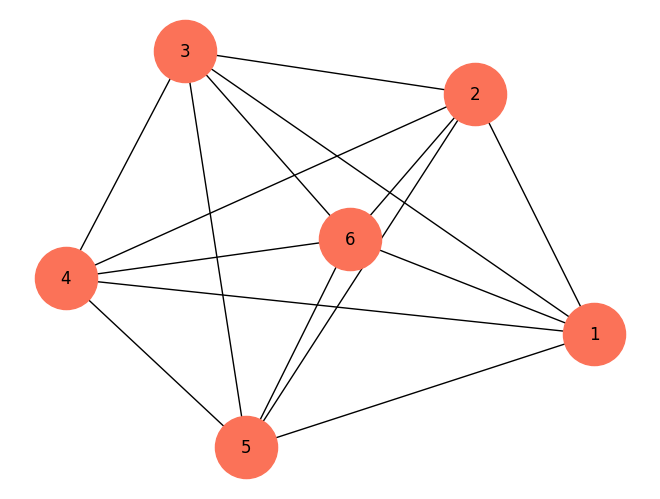

In [16]:
graph = nx.Graph()
graph.add_weighted_edges_from(distances)

nx.draw_kamada_kawai(graph, node_color='#fb7258',
                     node_size=2000, with_labels=True)

In [17]:
bestRoute, arrLength = chooseRoute(distances, V, Z, T, P)

print(f'Лучший выбранный маршрут: {bestRoute}')
print(f'Длина лучшего выбранного маршрута: {routeLength(bestRoute, distances)}')
print(f'Длины всех рассмотренных маршрутов: {arrLength}')

Лучший выбранный маршрут: [1, 3, 5, 2, 6, 4, 1]
Длина лучшего выбранного маршрута: 196
Длины всех рассмотренных маршрутов: [165, 150, 196, 164, 178]


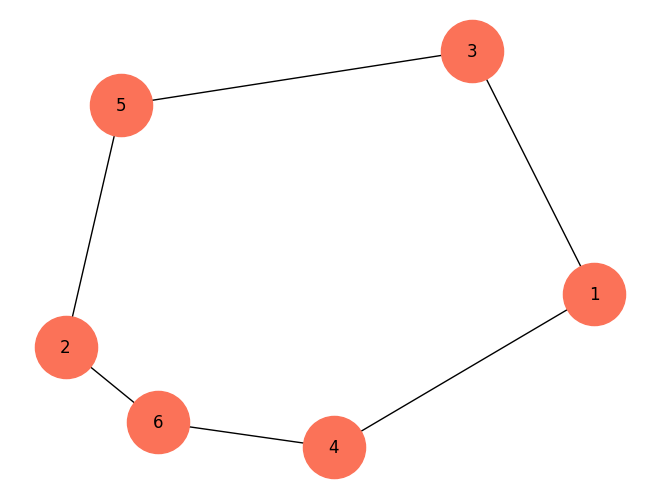

In [18]:
drawRouteGraph(distances, bestRoute)

In [19]:
P = [12, 31, 2, 31]

In [20]:
bestRoute, arrLength = chooseRoute(distances, V, Z, T, P)

print(f'Лучший выбранный маршрут: {bestRoute}')
print(f'Длина лучшего выбранного маршрута: {routeLength(bestRoute, distances)}')
print(f'Длины всех рассмотренных маршрутов: {arrLength}')

Лучший выбранный маршрут: [1, 3, 5, 2, 6, 4, 1]
Длина лучшего выбранного маршрута: 196
Длины всех рассмотренных маршрутов: [165, 150, 196, 164, 178]


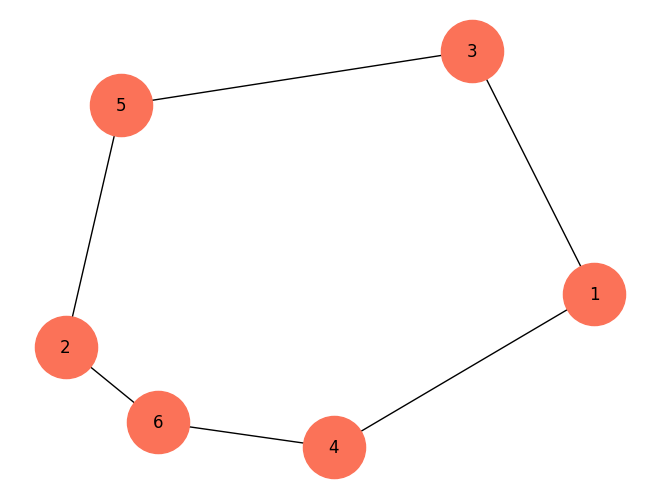

In [21]:
drawRouteGraph(distances, bestRoute)